## 1. Import bibliotek

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import export_graphviz, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, explained_variance_score

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.grid'] = True

## 2. Wczytanie nowego zbioru danych


In [2]:
data_path = 'vlagunr-Cyano.csv'
df = pd.read_csv(data_path)

print('Rozmiar danych:', df.shape)
display(df.head())
display(df.info())

Rozmiar danych: (156, 21)


,PSU,O2,temp.,SS,SRP,DOP,PP,NH4N,NO3N,DON,...,TN/TP,Fe,SiO4Si,ChlorophyceaeBiomassC,DiatomsBiomassC,PicoplanktonBiomassC,Windspeedinsitu,Depth,DIN to DIP,CyanobacteriaBiomassC
0,3.758,9.46,18.3,52.0,3.5,11.7,185.0,0.039,0.022,0.551,...,6.848,0.012,2.311,0.508,0.018,0.691,3.5,3.3,17.429,0.429
1,3.505,9.89,19.1,50.0,4.4,17.5,111.3,0.020,0.025,0.123,...,10.128,0.014,2.116,0.473,0.001,0.522,0.0,3.6,10.227,1.085
2,3.758,9.66,18.1,59.0,3.2,22.8,103.4,0.016,0.008,0.582,...,9.134,0.037,2.264,0.271,0.021,0.538,1.0,3.4,7.500,1.734
3,3.107,10.36,19.5,46.0,4.3,22.3,92.7,0.026,0.021,0.693,...,11.978,0.017,2.262,0.458,0.122,0.655,0.0,2.9,10.930,0.814
4,2.619,11.56,19.0,42.0,11.7,30.3,73.2,0.022,0.048,0.383,...,12.665,0.024,2.216,0.328,0.085,0.182,0.0,3.0,5.983,1.133


<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   PSU                    156 non-null    float64
 1   O2                     156 non-null    float64
 2   temp.                  156 non-null    float64
 3   SS                     156 non-null    float64
 4   SRP                    156 non-null    float64
 5   DOP                    156 non-null    float64
 6   PP                     156 non-null    float64
 7   NH4N                   156 non-null    float64
 8   NO3N                   156 non-null    float64
 9   DON                    156 non-null    float64
 10  PN                     156 non-null    float64
 11  TN/TP                  156 non-null    float64
 12  Fe                     156 non-null    float64
 13  SiO4Si                 156 non-null    float64
 14  ChlorophyceaeBiomassC  156 non-null    float64
 15  DiatomsBiomassC  

None

## 3. Kontrola danych

In [3]:
print('Kolumny w pliku:')
for i, col in enumerate(df.columns, 1):
    print(f'{i:02d}. {col}')

missing = df.isna().sum().sort_values(ascending=False)
print('\nBraki danych:')
display(missing.to_frame('liczba braków'))

print('\nStatystyki opisowe:')
display(df.describe().T)

Kolumny w pliku:
01. PSU
02. O2
03. temp.
04. SS
05. SRP
06. DOP
07. PP
08. NH4N
09. NO3N
10. DON
11. PN
12. TN/TP
13. Fe
14. SiO4Si
15. ChlorophyceaeBiomassC
16. DiatomsBiomassC
17. PicoplanktonBiomassC
18. Windspeedinsitu
19. Depth
20. DIN to DIP
21. CyanobacteriaBiomassC

Braki danych:


,liczba braków
PSU,0
TN/TP,0
DIN to DIP,0
Depth,0
Windspeedinsitu,0
PicoplanktonBiomassC,0
DiatomsBiomassC,0
ChlorophyceaeBiomassC,0
SiO4Si,0
Fe,0



Statystyki opisowe:


,count,mean,std,min,25%,50%,75%,max
PSU,156.0,3.356955,0.758863,1.400,2.80000,3.3790,3.95700,4.600
O2,156.0,10.180705,1.078504,7.620,9.36750,9.9550,10.89000,12.890
temp.,156.0,17.350000,3.122251,10.600,16.20000,17.9000,20.10000,20.700
SS,156.0,86.937115,35.506823,29.000,60.00000,80.0000,111.56250,217.500
SRP,156.0,15.035256,11.841528,0.100,7.47500,12.2500,19.87500,88.200
DOP,156.0,22.421154,19.531893,0.700,9.00000,15.7500,30.82500,91.100
PP,156.0,134.547436,51.210224,20.900,99.95000,131.5000,167.70000,285.100
NH4N,156.0,0.029429,0.017682,0.002,0.01900,0.0260,0.03500,0.106
NO3N,156.0,0.037071,0.020047,0.007,0.02400,0.0320,0.04425,0.142
DON,156.0,0.573897,0.173958,0.022,0.48600,0.5705,0.69925,0.975


## 4. Zmienna docelowa i zmienne objaśniające

In [4]:
target = 'CyanobacteriaBiomassC'

X = df.drop(columns=[target])
y = df[target]

# Upewniamy się, że model dostaje tylko dane numeryczne.
X = X.select_dtypes(include=[np.number]).copy()

print('Zmienna docelowa:', target)
print('Liczba zmiennych objaśniających:', X.shape[1])
print('Zmienne objaśniające:')
print(list(X.columns))

display(y.describe().to_frame('CyanobacteriaBiomassC'))

Zmienna docelowa: CyanobacteriaBiomassC
Liczba zmiennych objaśniających: 20
Zmienne objaśniające:
['PSU', 'O2', 'temp.', 'SS', 'SRP', 'DOP', 'PP', 'NH4N', 'NO3N', 'DON', 'PN', 'TN/TP', 'Fe', 'SiO4Si', 'ChlorophyceaeBiomassC', 'DiatomsBiomassC', 'PicoplanktonBiomassC', 'Windspeedinsitu', 'Depth', 'DIN to DIP']


,CyanobacteriaBiomassC
count,156.000000
mean,0.709897
std,0.530361
min,0.016000
25%,0.245000
50%,0.632500
75%,1.023000
max,2.862000


## 5. Podział na próbę treningową i testową


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (117, 20)
X_test : (39, 20)
y_train: (117,)
y_test : (39,)


## 6. Funkcja do obliczania miar regresji

Wymagane są następujące miary:

- Mean Absolute Error,
- Mean Absolute Error / Mean Ratio,
- Mean Squared Error,
- Explained Variance Score,
- Mean Absolute Percentage Error, MAPE,
- Accuracy = 1 - MAPE.

Dodatkowo dodanie RMSE

In [6]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    eps = 1e-12
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    evs = explained_variance_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), eps)))
    accuracy = 1 - mape
    mae_mean_ratio = mae / np.mean(np.abs(y_true))
    return {
        'MAE': mae,
        'MAE / Mean Ratio': mae_mean_ratio,
        'MSE': mse,
        'RMSE': rmse,
        'Explained Variance Score': evs,
        'MAPE': mape,
        'Accuracy = 1 - MAPE': accuracy
    }


def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    train_metrics = regression_metrics(y_train, pred_train)
    test_metrics = regression_metrics(y_test, pred_test)
    result = pd.DataFrame([train_metrics, test_metrics], index=['train', 'test'])
    result.insert(0, 'Model', model_name)
    return result


def fit_rf(X_train, y_train, **kwargs):
    params = dict(
        n_estimators=30,
        random_state=RANDOM_STATE,
        n_jobs=1,
        max_features='sqrt',
        min_samples_leaf=1
    )
    params.update(kwargs)
    model = RandomForestRegressor(**params)
    model.fit(X_train, y_train)
    return model

## 7. Model bazowy Random Forest — wszystkie zmienne

In [7]:
rf_all = fit_rf(X_train, y_train)
metrics_all = evaluate_model(rf_all, X_train, X_test, y_train, y_test, 'RF - wszystkie zmienne')
display(metrics_all.round(4))

,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - wszystkie zmienne,0.1042,0.1470,0.0224,0.1496,0.9183,0.284,0.716
test,RF - wszystkie zmienne,0.3472,0.4861,0.2288,0.4783,0.2331,0.707,0.293


## 8. Ważność zmiennych / Feature Importances

Ranking ważności zmiennych:


,Feature,Importance
0,PN,0.113467
1,PSU,0.094658
2,NH4N,0.083656
3,NO3N,0.083252
4,PicoplanktonBiomassC,0.072295
5,temp.,0.061517
6,DON,0.051854
7,O2,0.046149
8,PP,0.045441
9,SS,0.042711


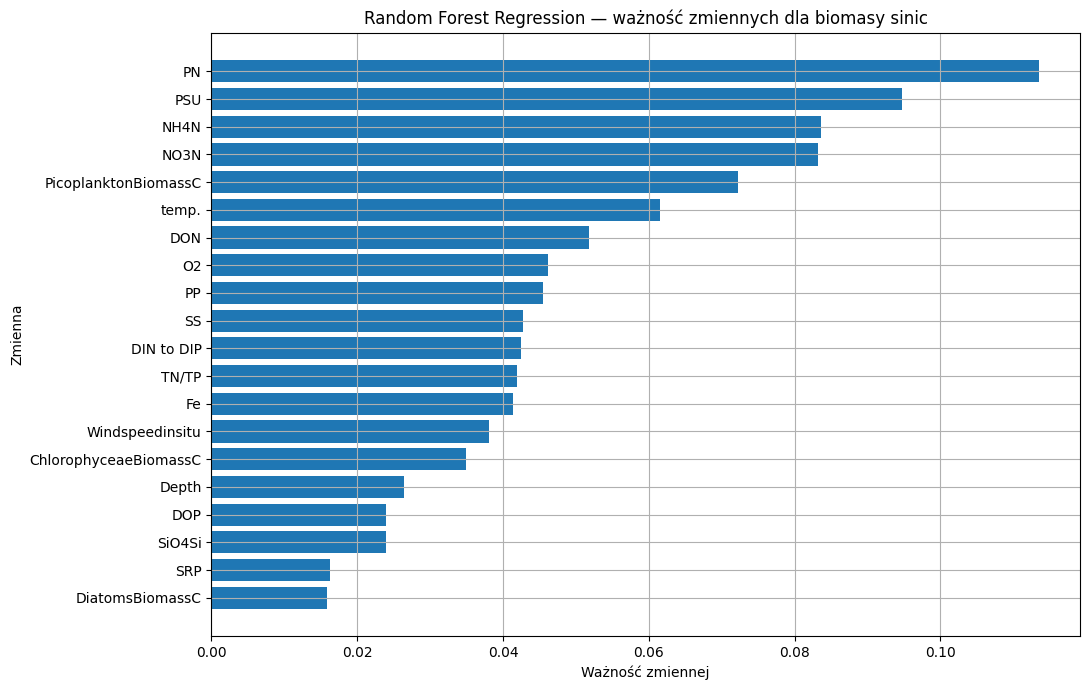

In [8]:
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_all.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print('Ranking ważności zmiennych:')
display(importances)

plt.figure(figsize=(11, 7))
plt.barh(importances['Feature'][::-1], importances['Importance'][::-1])
plt.xlabel('Ważność zmiennej')
plt.ylabel('Zmienna')
plt.title('Random Forest Regression — ważność zmiennych dla biomasy sinic')
plt.tight_layout()
plt.show()

## 9. Model dla dwóch najważniejszych zmiennych


In [9]:
top2_features = importances.head(2)['Feature'].tolist()
print('Dwie najważniejsze zmienne:', top2_features)

X_train_top2 = X_train[top2_features]
X_test_top2 = X_test[top2_features]

rf_top2 = fit_rf(X_train_top2, y_train)
metrics_top2 = evaluate_model(rf_top2, X_train_top2, X_test_top2, y_train, y_test, 'RF - 2 najważniejsze zmienne')
display(metrics_top2.round(4))

Dwie najważniejsze zmienne: ['PN', 'PSU']


,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - 2 najważniejsze zmienne,0.1159,0.1636,0.0303,0.1741,0.8897,0.3167,0.6833
test,RF - 2 najważniejsze zmienne,0.3725,0.5216,0.2380,0.4878,0.2290,0.7233,0.2767


## 10. Model po usunięciu 10% najmniej ważnych zmiennych


Liczba wszystkich cech: 20
Liczba usuniętych cech 10%: 2
Usunięte najmniej ważne cechy: ['SRP', 'DiatomsBiomassC']
Pozostawione cechy: ['PN', 'PSU', 'NH4N', 'NO3N', 'PicoplanktonBiomassC', 'temp.', 'DON', 'O2', 'PP', 'SS', 'DIN to DIP', 'TN/TP', 'Fe', 'Windspeedinsitu', 'ChlorophyceaeBiomassC', 'Depth', 'DOP', 'SiO4Si']


,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - redukcja 10% cech,0.1073,0.1514,0.0243,0.1559,0.9115,0.2820,0.7180
test,RF - redukcja 10% cech,0.3562,0.4987,0.2458,0.4958,0.1758,0.7639,0.2361


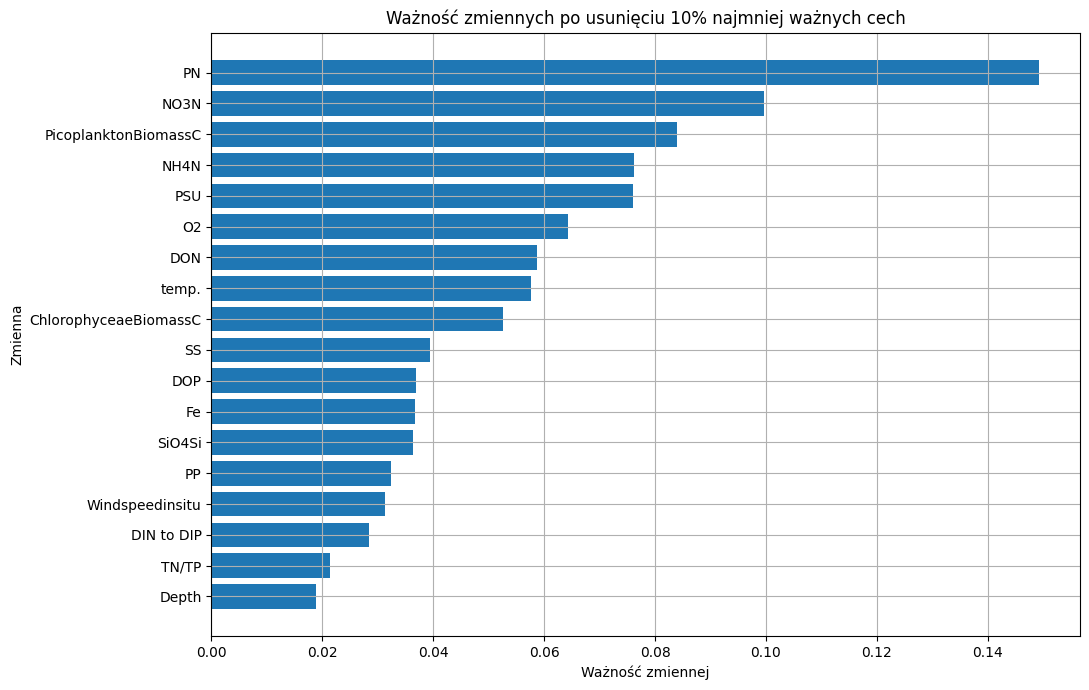

In [10]:
n_features = len(importances)
n_remove = max(1, int(np.ceil(0.10 * n_features)))
removed_features = importances.tail(n_remove)['Feature'].tolist()
selected_reduced_features = importances.iloc[:-n_remove]['Feature'].tolist()

print(f'Liczba wszystkich cech: {n_features}')
print(f'Liczba usuniętych cech 10%: {n_remove}')
print('Usunięte najmniej ważne cechy:', removed_features)
print('Pozostawione cechy:', selected_reduced_features)

X_train_reduced = X_train[selected_reduced_features]
X_test_reduced = X_test[selected_reduced_features]

rf_reduced = fit_rf(X_train_reduced, y_train)
metrics_reduced = evaluate_model(rf_reduced, X_train_reduced, X_test_reduced, y_train, y_test, 'RF - redukcja 10% cech')
display(metrics_reduced.round(4))

reduced_importances = pd.DataFrame({
    'Feature': selected_reduced_features,
    'Importance': rf_reduced.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(11, 7))
plt.barh(reduced_importances['Feature'][::-1], reduced_importances['Importance'][::-1])
plt.xlabel('Ważność zmiennej')
plt.ylabel('Zmienna')
plt.title('Ważność zmiennych po usunięciu 10% najmniej ważnych cech')
plt.tight_layout()
plt.show()

## 11. Porównanie modeli bazowych

wyniki trzech wariantów wymaganych w prezentacji:

1. wszystkie zmienne,
2. dwie najważniejsze zmienne,
3. zmienne po odrzuceniu 10% najmniej ważnych cech.

In [11]:
comparison_basic = pd.concat([metrics_all, metrics_top2, metrics_reduced], axis=0)
display(comparison_basic.round(4))

best_basic = comparison_basic[comparison_basic.index == 'test'].sort_values('Accuracy = 1 - MAPE', ascending=False).head(1)
print('Najlepszy model bazowy według Accuracy = 1 - MAPE dla próby testowej:')
display(best_basic.round(4))

,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - wszystkie zmienne,0.1042,0.1470,0.0224,0.1496,0.9183,0.2840,0.7160
test,RF - wszystkie zmienne,0.3472,0.4861,0.2288,0.4783,0.2331,0.7070,0.2930
train,RF - 2 najważniejsze zmienne,0.1159,0.1636,0.0303,0.1741,0.8897,0.3167,0.6833
test,RF - 2 najważniejsze zmienne,0.3725,0.5216,0.2380,0.4878,0.2290,0.7233,0.2767
train,RF - redukcja 10% cech,0.1073,0.1514,0.0243,0.1559,0.9115,0.2820,0.7180
test,RF - redukcja 10% cech,0.3562,0.4987,0.2458,0.4958,0.1758,0.7639,0.2361


Najlepszy model bazowy według Accuracy = 1 - MAPE dla próby testowej:


,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
test,RF - wszystkie zmienne,0.3472,0.4861,0.2288,0.4783,0.2331,0.707,0.293


## 12. Wizualizacja drzewa decyzyjnego z lasu losowego

Plik DOT zapisano jako: cyano_random_forest_tree.dot
Ten kod można wkleić do WebGraphviz: http://www.webgraphviz.com/?tab=map
digraph Tree {
node [shape=box, style="filled, rounded", color="black", fontname="helvetica"] ;
edge [fontname="helvetica"] ;
0 [label=<PSU &le; 2.45<br/>squared_error = 0.291<br/>samples = 73<br/>value = 0.691>, fillcolor="#f9e1d0"] ;
1 [label=<DIN to DIP &le; 1.266<br/>squared_error = 0.055<br/>samples = 12<br/>value = 0.241>, fillcolor="#fdf5ef"] ;
0 -> 1 [labeldistance=2.5, labelangle=45, headlabel="True"] ;
2 [label=<squared_error = 0.0<br/>samples = 1<br/>value = 0.773>, fillcolor="#f8ddca"] ;
1 -> 2 ;
3 [label=<DIN to DIP &le; 3.339<br/>squared_error = 0.019<br/>samples = 11<br/>value = 0.168>, fillcolor="#fef8f4"] ;
1 -> 3 ;
4 [label=<Fe &le; 0.057<br/>squared_error = 0.008<br/>samples = 3<br/>value = 0.336>, fillcolor="#fcf1e9"] ;
3 -> 4 ;
5 [label=<squared_error = 0.0<br/>samples = 1<br/>value = 0.496>, fillcolor="#fbeade"] ;
4 -> 5 ;
6 [label=<Picopla

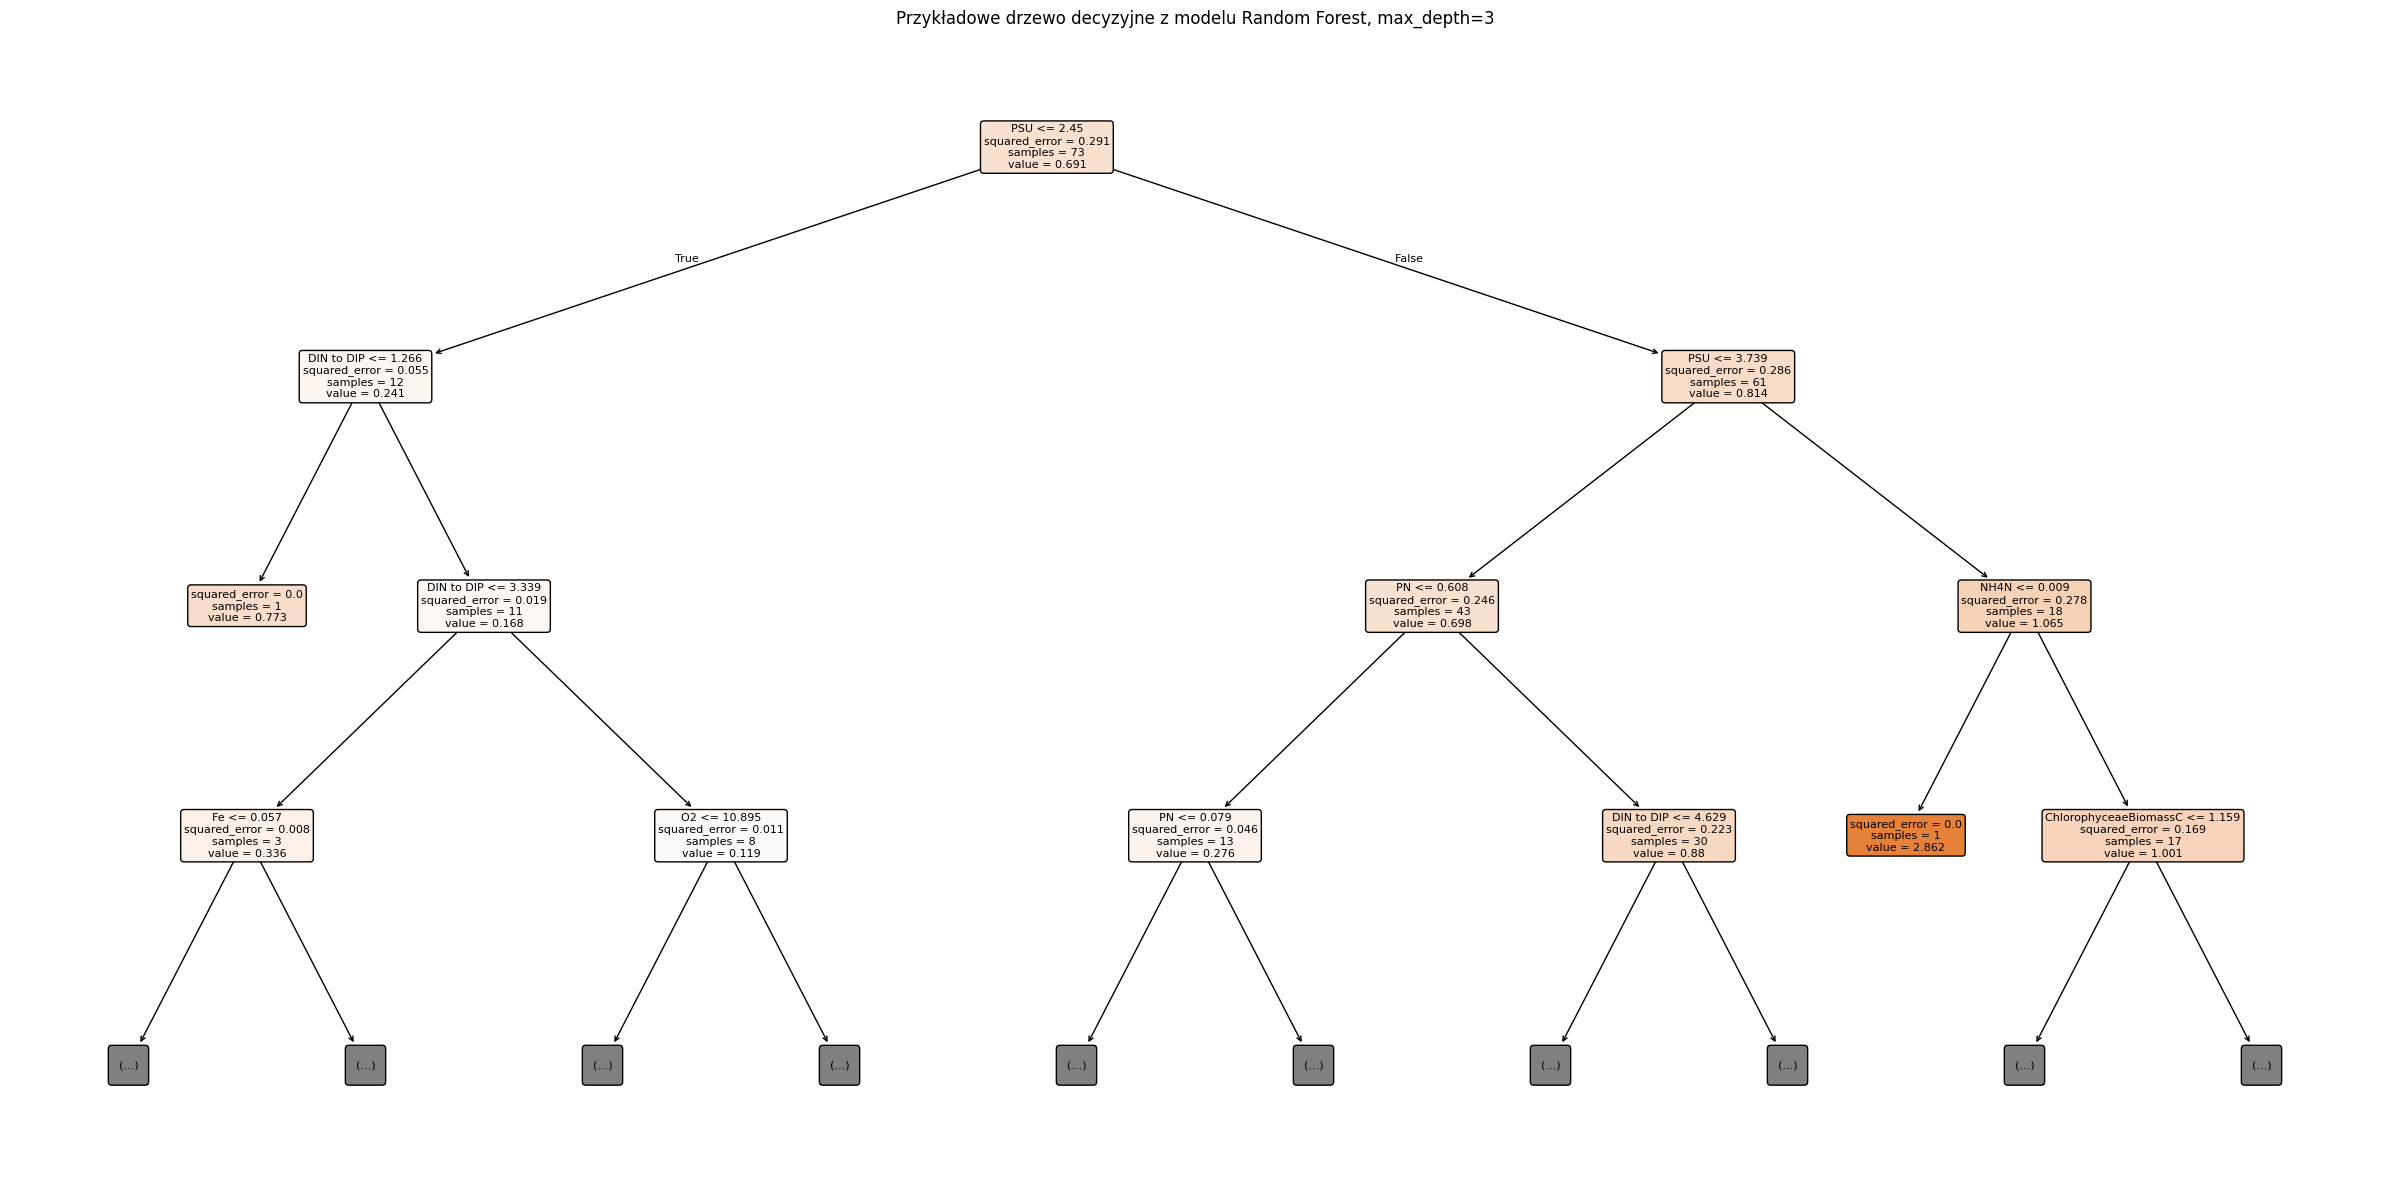

Obraz drzewa zapisano jako: cyano_random_forest_tree.png


In [12]:
tree_index = 0
single_tree = rf_all.estimators_[tree_index]

dot_path = 'cyano_random_forest_tree.dot'
png_path = 'cyano_random_forest_tree.png'

export_graphviz(
    single_tree,
    out_file=dot_path,
    feature_names=list(X.columns),
    filled=True,
    rounded=True,
    special_characters=True,
    max_depth=4
)

print('Plik DOT zapisano jako:', dot_path)
print('Ten kod można wkleić do WebGraphviz: http://www.webgraphviz.com/?tab=map')

# Podgląd pierwszych linii pliku DOT.
with open(dot_path, 'r', encoding='utf-8') as f:
    dot_preview = ''.join(f.readlines()[:25])
print(dot_preview)

plt.figure(figsize=(24, 12))
plot_tree(
    single_tree,
    feature_names=list(X.columns),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title('Przykładowe drzewo decyzyjne z modelu Random Forest, max_depth=3')
plt.tight_layout()
plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.show()
print('Obraz drzewa zapisano jako:', png_path)

## 13. Relacje między zmienną docelową a czterema najważniejszymi zmiennymi

Wykresy:

1. scatter plot 2x2,
2. wykresy z linią trendu,
3. porównanie wartości rzeczywistych i przewidywanych względem dwóch najważniejszych cech.

Cztery najważniejsze zmienne: ['PN', 'PSU', 'NH4N', 'NO3N']


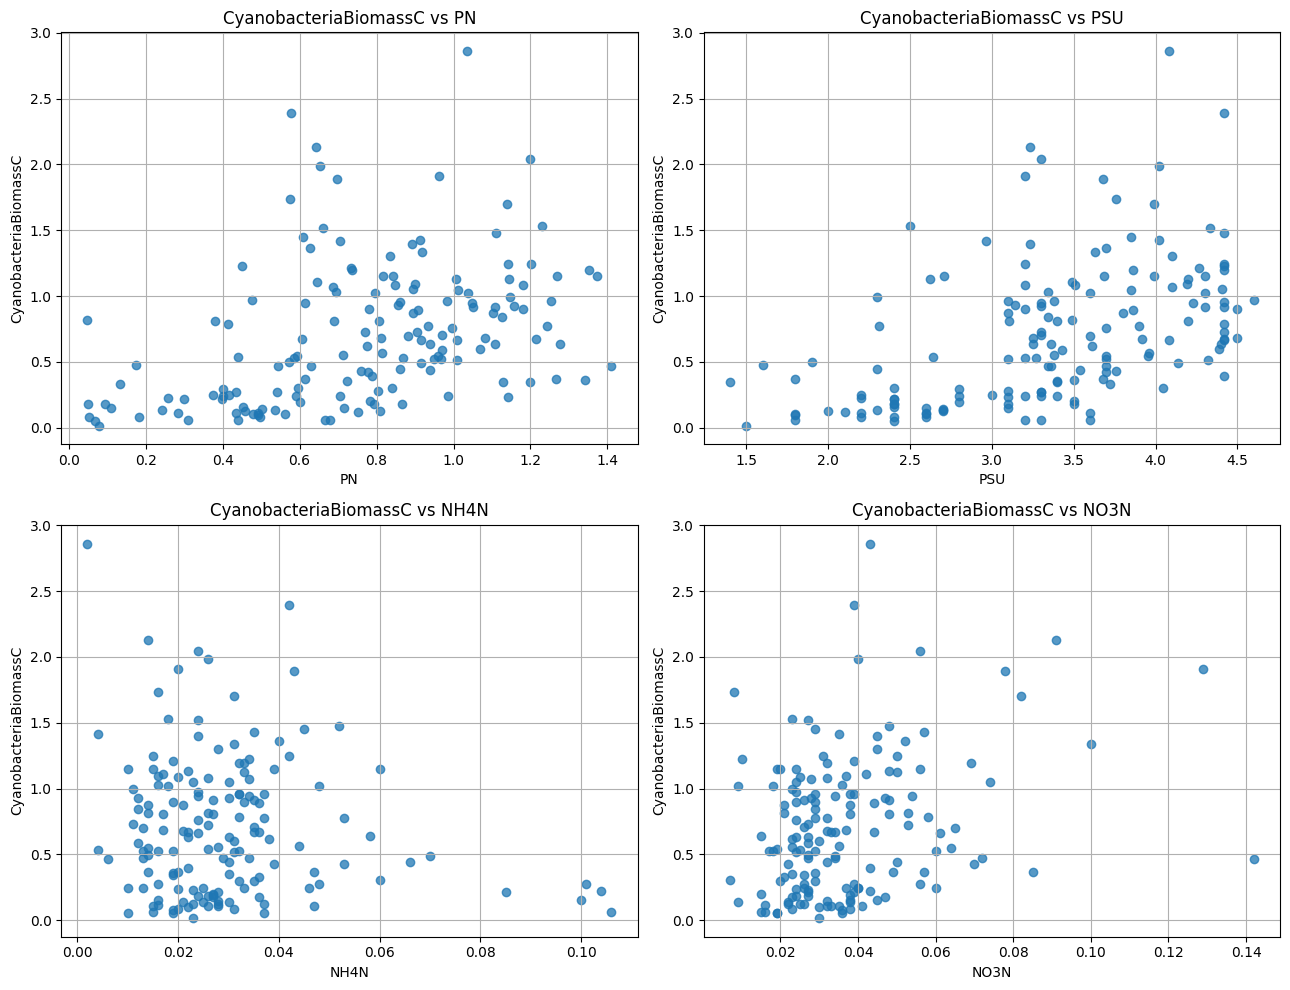

In [13]:
top4_features = importances.head(4)['Feature'].tolist()
print('Cztery najważniejsze zmienne:', top4_features)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()
for ax, feature in zip(axes, top4_features):
    ax.scatter(df[feature], df[target], alpha=0.75)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.set_title(f'{target} vs {feature}')
plt.tight_layout()
plt.show()

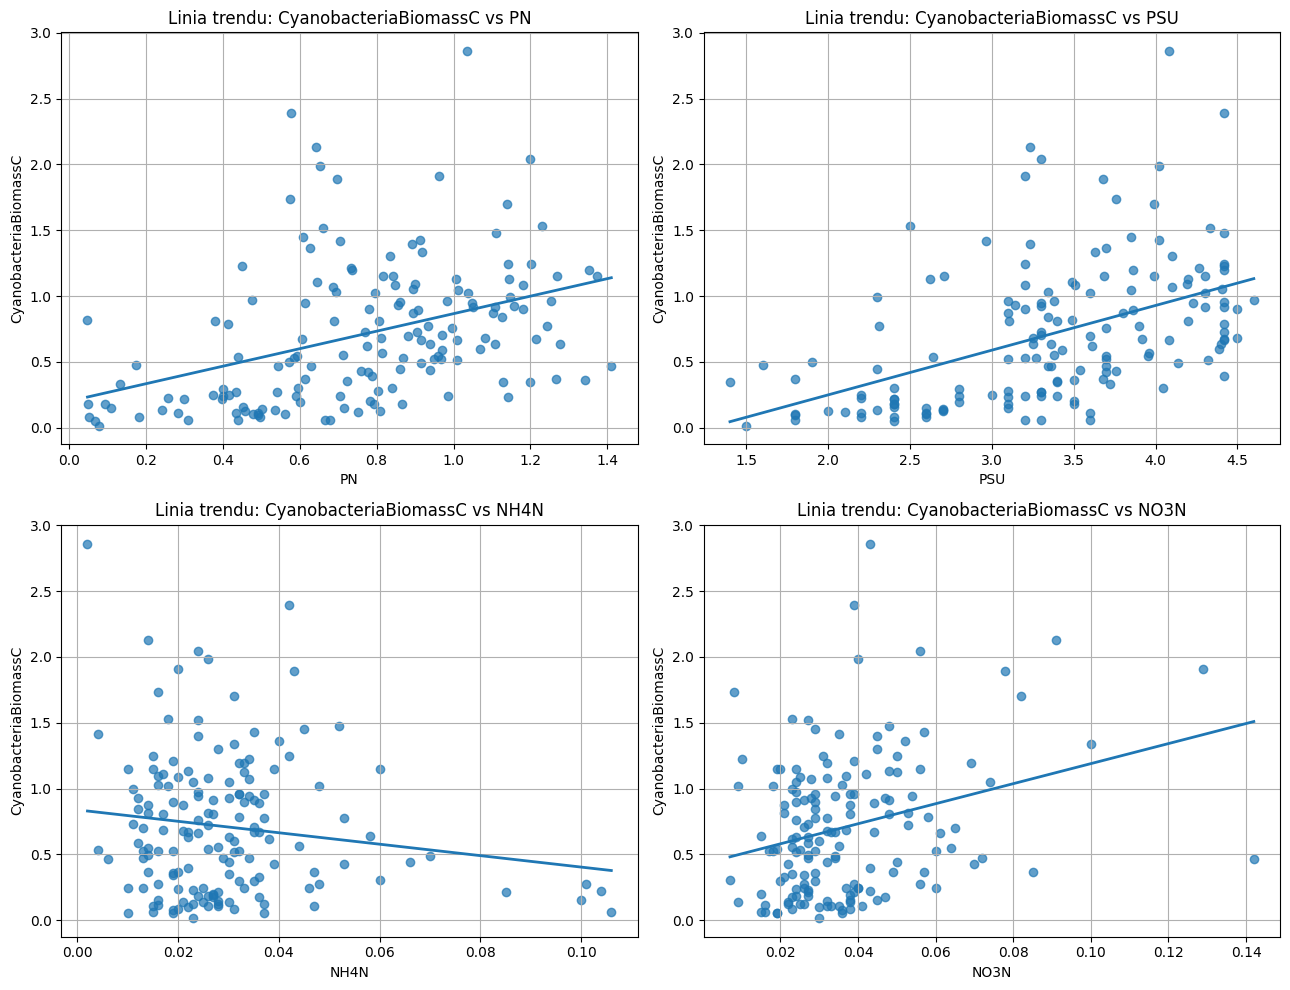

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()
for ax, feature in zip(axes, top4_features):
    x = df[feature].values
    yy = df[target].values
    ax.scatter(x, yy, alpha=0.7)
    if len(np.unique(x)) > 1:
        coef = np.polyfit(x, yy, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        y_line = coef[0] * x_line + coef[1]
        ax.plot(x_line, y_line, linewidth=2)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.set_title(f'Linia trendu: {target} vs {feature}')
plt.tight_layout()
plt.show()

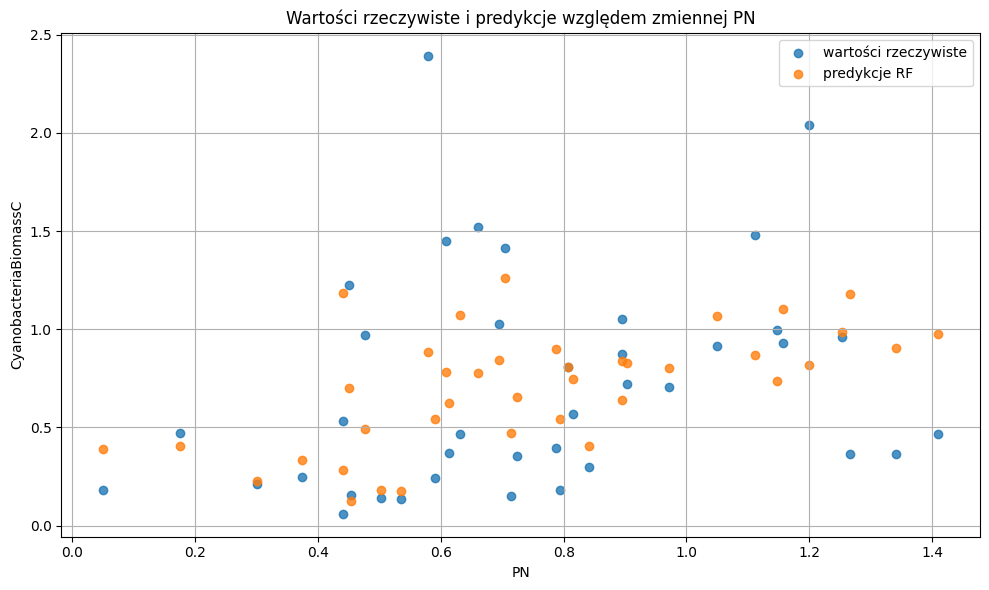

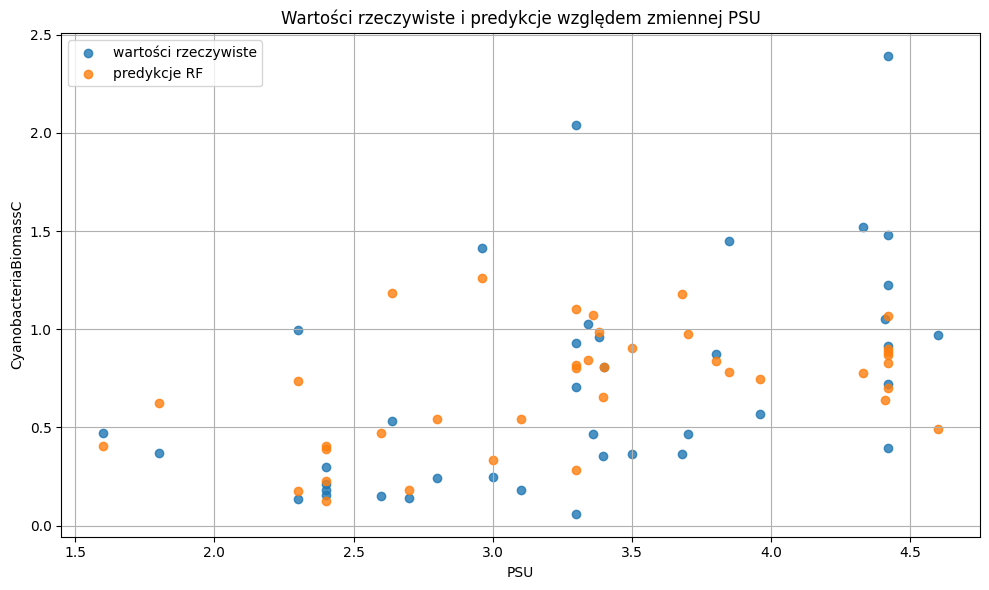

In [15]:
test_predictions = rf_all.predict(X_test)
plot_df = X_test[top2_features].copy()
plot_df['observed'] = y_test.values
plot_df['predicted'] = test_predictions

for feature in top2_features:
    plt.figure(figsize=(10, 6))
    plt.scatter(plot_df[feature], plot_df['observed'], label='wartości rzeczywiste', alpha=0.8)
    plt.scatter(plot_df[feature], plot_df['predicted'], label='predykcje RF', alpha=0.8)
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.title(f'Wartości rzeczywiste i predykcje względem zmiennej {feature}')
    plt.legend()
    plt.tight_layout()
    plt.show()

## 14. RandomizedSearchCV — 3-krotna walidacja krzyżowa

In [16]:
base_rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)

random_grid = {
    'n_estimators': [10, 20, 30],
    'max_features': ['sqrt', 0.8],
    'max_depth': [None, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

random_search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=random_grid,
    n_iter=12,
    cv=3,
    scoring='neg_mean_absolute_error',
    verbose=0,
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=True
)

random_search.fit(X_train_reduced, y_train)

print('Najlepsze parametry RandomizedSearchCV:')
print(random_search.best_params_)
print('Najlepszy wynik CV (neg MAE):', random_search.best_score_)

rf_random_best = random_search.best_estimator_
metrics_random = evaluate_model(
    rf_random_best, X_train_reduced, X_test_reduced, y_train, y_test,
    'RF - RandomizedSearchCV 3-fold'
)
display(metrics_random.round(4))

Najlepsze parametry RandomizedSearchCV:
{'n_estimators': 30, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5, 'bootstrap': False}
Najlepszy wynik CV (neg MAE): -0.28813957707095217


,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - RandomizedSearchCV 3-fold,0.1642,0.2318,0.0431,0.2077,0.8422,0.4634,0.5366
test,RF - RandomizedSearchCV 3-fold,0.3811,0.5336,0.2697,0.5193,0.0998,0.8134,0.1866


## 15. GridSearchCV — 3-krotna walidacja krzyżowa

In [17]:
param_grid = {
    'n_estimators': [10, 20, 30],
    'max_features': ['sqrt', 0.8],
    'max_depth': [None, 5],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True]
}

n_grid_combinations = np.prod([len(v) for v in param_grid.values()])
print('Liczba kombinacji parametrów w GridSearchCV:', n_grid_combinations)
print('Liczba dopasowań przy 3-fold CV:', n_grid_combinations * 3)

grid_search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    verbose=0,
    n_jobs=1,
    return_train_score=True
)

grid_search.fit(X_train_reduced, y_train)

print('Najlepsze parametry GridSearchCV:')
print(grid_search.best_params_)
print('Najlepszy wynik CV (neg MAE):', grid_search.best_score_)

rf_grid_best = grid_search.best_estimator_
metrics_grid = evaluate_model(
    rf_grid_best, X_train_reduced, X_test_reduced, y_train, y_test,
    'RF - GridSearchCV 3-fold'
)
display(metrics_grid.round(4))

Liczba kombinacji parametrów w GridSearchCV: 48
Liczba dopasowań przy 3-fold CV: 144
Najlepsze parametry GridSearchCV:
{'bootstrap': True, 'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 10}
Najlepszy wynik CV (neg MAE): -0.2830478632478632


,Model,MAE,MAE / Mean Ratio,MSE,RMSE,Explained Variance Score,MAPE,Accuracy = 1 - MAPE
train,RF - GridSearchCV 3-fold,0.1131,0.1597,0.0275,0.1658,0.8996,0.3357,0.6643
test,RF - GridSearchCV 3-fold,0.3779,0.5291,0.2624,0.5123,0.1230,0.8796,0.1204


## 16. Porównanie wszystkich modeli

Porównanie wyników dla próby treningowej i testowej dla modeli:

- wszystkie zmienne,
- 2 najważniejsze zmienne,
- po redukcji 10% najmniej ważnych cech,
- po RandomizedSearchCV,
- po GridSearchCV.

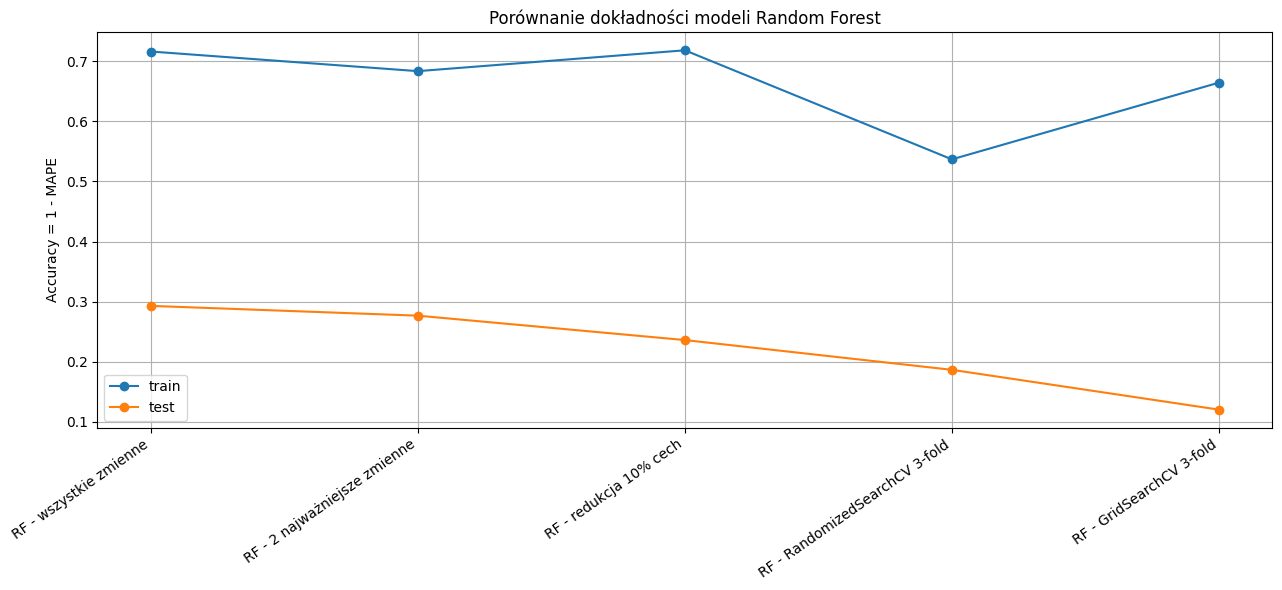

In [19]:
plot_results = all_results.reset_index().rename(columns={'index': 'Dataset'})

plt.figure(figsize=(13, 6))
for dataset_name in ['train', 'test']:
    subset = plot_results[plot_results['Dataset'] == dataset_name]
    plt.plot(subset['Model'], subset['Accuracy = 1 - MAPE'], marker='o', label=dataset_name)
plt.xticks(rotation=35, ha='right')
plt.ylabel('Accuracy = 1 - MAPE')
plt.title('Porównanie dokładności modeli Random Forest')
plt.legend()
plt.tight_layout()
plt.show()